# Week 2 — Data Preprocessing & Feature Engineering

## Day 1: Data Inspection, Cleaning & Alignment

**Objective:** Prepare a consistent and reproducible market dataset
for chooser option pricing and subsequent machine learning models.

**Initial Research Period:** 2018–2024

**Underlying Asset:** JPMorgan Chase & Co. (JPM)

In [1]:
import pandas as pd
from pathlib import Path

raw_dir = Path.home() / "Desktop/Chooser_Option_Research/02_Data/raw"

print("Directory exists:", raw_dir.exists())

for file in raw_dir.glob("*.csv"):
    print(file.name)

Directory exists: True
JPM_AlphaVantage_daily_latest_100_days.csv
VIX_daily_2018_2024.csv
DGS1_2018_2024.csv
JPM_daily_2018_2024.csv
JPM_Nasdaq_2016_2026.csv
DGS6MO_2018_2024.csv


In [2]:
# Load raw datasets
jpm = pd.read_csv(raw_dir / "JPM_daily_2018_2024.csv")
vix = pd.read_csv(raw_dir / "VIX_daily_2018_2024.csv")

dgs1 = pd.read_csv(raw_dir / "DGS1_2018_2024.csv")
dgs6mo = pd.read_csv(raw_dir / "DGS6MO_2018_2024.csv")

In [3]:
for name, df in [("JPM", jpm), ("VIX", vix),
                 ("DGS1", dgs1), ("DGS6MO", dgs6mo)]:

    print(name, df.shape)
    print(df.dtypes)
    print()

JPM (1761, 9)
Date                str
Open            float64
High            float64
Low             float64
Close           float64
Adj Close       float64
Volume            int64
Dividends       float64
Stock Splits    float64
dtype: object

VIX (1761, 9)
Date                str
Open            float64
High            float64
Low             float64
Close           float64
Adj Close       float64
Volume            int64
Dividends       float64
Stock Splits    float64
dtype: object

DGS1 (1827, 5)
Unnamed: 0        int64
realtime_start      str
realtime_end        str
date                str
value               str
dtype: object

DGS6MO (1827, 5)
Unnamed: 0        int64
realtime_start      str
realtime_end        str
date                str
value               str
dtype: object



In [4]:
for name, df in [("JPM", jpm), ("VIX", vix),
                 ("DGS1", dgs1), ("DGS6MO", dgs6mo)]:
    print(name)
    print(df.isna().sum())
    print()

JPM
Date            0
Open            0
High            0
Low             0
Close           0
Adj Close       0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

VIX
Date            0
Open            0
High            0
Low             0
Close           0
Adj Close       0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

DGS1
Unnamed: 0        0
realtime_start    0
realtime_end      0
date              0
value             0
dtype: int64

DGS6MO
Unnamed: 0        0
realtime_start    0
realtime_end      0
date              0
value             0
dtype: int64



In [5]:
print("DGS1 missing markers:", (dgs1["value"] == ".").sum())
print("DGS6MO missing markers:", (dgs6mo["value"] == ".").sum())

DGS1 missing markers: 77
DGS6MO missing markers: 77


In [6]:
jpm_clean = jpm.copy()
vix_clean = vix.copy()

dgs1_clean = dgs1[["date", "value"]].copy()
dgs6mo_clean = dgs6mo[["date", "value"]].copy()

In [7]:
jpm_clean["Date"] = pd.to_datetime(jpm_clean["Date"].str[:10])
vix_clean["Date"] = pd.to_datetime(vix_clean["Date"].str[:10])

dgs1_clean["date"] = pd.to_datetime(dgs1_clean["date"])
dgs6mo_clean["date"] = pd.to_datetime(dgs6mo_clean["date"])

In [8]:
dgs1_clean["value"] = pd.to_numeric(dgs1_clean["value"], errors="coerce")

dgs6mo_clean["value"] = pd.to_numeric(dgs6mo_clean["value"], errors="coerce")

In [9]:
dgs1_clean["value"] = dgs1_clean["value"] / 100

dgs6mo_clean["value"] = dgs6mo_clean["value"] / 100

In [10]:
print("JPM Date:", jpm_clean["Date"].dtype)
print("VIX Date:", vix_clean["Date"].dtype)

print("DGS1 value:", dgs1_clean["value"].dtype)
print("DGS6MO value:", dgs6mo_clean["value"].dtype)

print("DGS1 missing:", dgs1_clean["value"].isna().sum())
print("DGS6MO missing:", dgs6mo_clean["value"].isna().sum())

display(dgs1_clean.head())

JPM Date: datetime64[us]
VIX Date: datetime64[us]
DGS1 value: float64
DGS6MO value: float64
DGS1 missing: 77
DGS6MO missing: 77


,date,value
0,2018-01-01,NaN
1,2018-01-02,0.0183
2,2018-01-03,0.0181
3,2018-01-04,0.0182
4,2018-01-05,0.0180


In [11]:
#data alignmnet
vix_part = vix_clean[["Date", "Close"]].rename(
    columns={"Close": "VIX_Close"}
)

dgs1_part = dgs1_clean.rename(
    columns={"date": "Date", "value": "DGS1"}
)

dgs6mo_part = dgs6mo_clean.rename(
    columns={"date": "Date", "value": "DGS6MO"}
)

In [12]:
aligned = pd.merge(jpm_clean, vix_part, on="Date", how="left")

aligned = pd.merge(aligned, dgs1_part, on="Date", how="left")

aligned = pd.merge(aligned, dgs6mo_part, on="Date", how="left")

In [13]:
aligned = aligned.sort_values("Date").reset_index(drop=True)

print("Shape:", aligned.shape)

display(
    aligned[["Date", "Close", "VIX_Close", "DGS1", "DGS6MO"]].head(10)
)

Shape: (1761, 12)


,Date,Close,VIX_Close,DGS1,DGS6MO
0,2018-01-02,107.949997,9.77,0.0183,0.0161
1,2018-01-03,108.059998,9.15,0.0181,0.0159
2,2018-01-04,109.040001,9.22,0.0182,0.0160
3,2018-01-05,108.339996,9.22,0.0180,0.0158
4,2018-01-08,108.500000,9.52,0.0179,0.0160
5,2018-01-09,109.050003,10.08,0.0178,0.0160
6,2018-01-10,110.250000,9.82,0.0178,0.0159
7,2018-01-11,110.839996,9.88,0.0177,0.0158
8,2018-01-12,112.669998,10.16,0.0178,0.0159
9,2018-01-16,112.269997,11.66,0.0179,0.0163


In [14]:
print("Missing values:")
print(aligned[["VIX_Close", "DGS1", "DGS6MO"]].isna().sum())

print("Duplicate dates:", aligned["Date"].duplicated().sum())

Missing values:
VIX_Close     0
DGS1         13
DGS6MO       13
dtype: int64
Duplicate dates: 0


In [15]:
#missing data investigation
missing_rates = aligned[
    aligned["DGS1"].isna() | aligned["DGS6MO"].isna()
]

display(missing_rates[["Date", "DGS1", "DGS6MO"]])

,Date,DGS1,DGS6MO
193,2018-10-08,NaN,NaN
218,2018-11-12,NaN,NaN
448,2019-10-14,NaN,NaN
468,2019-11-11,NaN,NaN
699,2020-10-12,NaN,NaN
721,2020-11-11,NaN,NaN
950,2021-10-11,NaN,NaN
973,2021-11-11,NaN,NaN
1201,2022-10-10,NaN,NaN
1225,2022-11-11,NaN,NaN


In [16]:
#forward fill
aligned_filled = aligned.copy()

# Record originally missing Treasury rates
aligned_filled["rate_ffilled"] = aligned_filled["DGS1"].isna() | aligned_filled["DGS6MO"].isna()

# Forward fill
aligned_filled[["DGS1", "DGS6MO"]] = aligned_filled[["DGS1", "DGS6MO"]].ffill()

In [17]:
print("Missing after filling:")
print(aligned_filled[["DGS1", "DGS6MO"]].isna().sum())

print("Filled dates:", aligned_filled["rate_ffilled"].sum())
print("Duplicate dates:", aligned_filled["Date"].duplicated().sum())

display(
    aligned_filled.loc[
        missing_rates.index,
        ["Date", "DGS1", "DGS6MO", "rate_ffilled"]
    ]
)

Missing after filling:
DGS1      0
DGS6MO    0
dtype: int64
Filled dates: 13
Duplicate dates: 0


,Date,DGS1,DGS6MO,rate_ffilled
193,2018-10-08,0.0264,0.0241,True
218,2018-11-12,0.0273,0.0252,True
448,2019-10-14,0.0167,0.0168,True
468,2019-11-11,0.0158,0.0158,True
699,2020-10-12,0.0015,0.0012,True
721,2020-11-11,0.0012,0.0011,True
950,2021-10-11,0.0009,0.0007,True
973,2021-11-11,0.0017,0.0007,True
1201,2022-10-10,0.0424,0.0409,True
1225,2022-11-11,0.0459,0.0452,True


In [18]:
processed_dir = raw_dir.parent / "processed"
processed_dir.mkdir(exist_ok=True)

aligned_filled.to_csv(
    processed_dir / "W02_Aligned_Market_Data.csv",
    index=False
)

## Trading Calendar Alignment and Missing Rate Treatment
After aligning JPM, VIX, and Treasury yield observations using JPM trading dates, 13 missing observations were identified in both Treasury series. These dates were consistent with U.S. government and Treasury market holidays during which equity markets remained open. **Forward filling** was applied using the most recent available Treasury yield, while preserving the original missing-value status through an imputation indicator. This approach avoids discarding valid equity trading observations and provides a consistent preliminary daily dataset. The timing and availability assumptions will be reviewed before predictive modeling.

In [19]:
print((processed_dir / "W02_Aligned_Market_Data.csv").exists())
print(aligned_filled.shape)

True
(1761, 13)


## Feature Engineering
Transform raw market observations into informative variables that can be used for statistical modeling, volatility forecasting, and option pricing.

In [20]:
## Feature 1 — Simple Return
features = aligned_filled.copy()
features["return_1d"] = features["Adj Close"].pct_change()

In [21]:
## Feature 2 — Log Return
import numpy as np

features["log_return_1d"] = np.log(
    features["Adj Close"] / features["Adj Close"].shift(1)
)

In [22]:
display(
    features[
        ["Date", "Adj Close", "return_1d", "log_return_1d"]
    ].head(10)
)

,Date,Adj Close,return_1d,log_return_1d
0,2018-01-02,85.091499,NaN,NaN
1,2018-01-03,85.178230,0.001019,0.001019
2,2018-01-04,86.398468,0.014326,0.014224
3,2018-01-05,85.843803,-0.006420,-0.006441
4,2018-01-08,85.970566,0.001477,0.001476
5,2018-01-09,86.406364,0.005069,0.005056
6,2018-01-10,87.357201,0.011004,0.010944
7,2018-01-11,87.824684,0.005351,0.005337
8,2018-01-12,89.274704,0.016510,0.016376
9,2018-01-16,88.957756,-0.003550,-0.003557


In [23]:
# Feature 3: 5-day return
features["return_5d"] = features["Adj Close"].pct_change(5)

# Feature 4: 20-day return
features["return_20d"] = features["Adj Close"].pct_change(20)

In [24]:
display(
    features[
        ["Date", "Adj Close", "return_1d",
         "return_5d", "return_20d"]
    ].head(25)
)

,Date,Adj Close,return_1d,return_5d,return_20d
0,2018-01-02,85.091499,NaN,NaN,NaN
1,2018-01-03,85.178230,0.001019,NaN,NaN
2,2018-01-04,86.398468,0.014326,NaN,NaN
3,2018-01-05,85.843803,-0.006420,NaN,NaN
4,2018-01-08,85.970566,0.001477,NaN,NaN
5,2018-01-09,86.406364,0.005069,0.015452,NaN
6,2018-01-10,87.357201,0.011004,0.025581,NaN
7,2018-01-11,87.824684,0.005351,0.016507,NaN
8,2018-01-12,89.274704,0.016510,0.039967,NaN
9,2018-01-16,88.957756,-0.003550,0.034747,NaN


In [25]:
# Feature 5: 5-day rolling volatility
features["volatility_5d"] = (
    features["log_return_1d"].rolling(5).std() * np.sqrt(252)
)

# Feature 6: 20-day rolling volatility
features["volatility_20d"] = (
    features["log_return_1d"].rolling(20).std() * np.sqrt(252)
)

In [26]:
print(
    features[["volatility_5d", "volatility_20d"]]
    .isna().sum()
)

display(
    features[
        ["Date", "log_return_1d",
         "volatility_5d", "volatility_20d"]
    ].iloc[18:26]
)

volatility_5d      5
volatility_20d    20
dtype: int64


,Date,log_return_1d,volatility_5d,volatility_20d
18,2018-01-29,-0.001032,0.093750,NaN
19,2018-01-30,-0.009425,0.129830,NaN
20,2018-01-31,0.004853,0.094608,0.110264
21,2018-02-01,0.010321,0.119924,0.112177
22,2018-02-02,-0.022411,0.203850,0.140471
23,2018-02-05,-0.049140,0.378159,0.229473
24,2018-02-06,0.029969,0.489652,0.252671
25,2018-02-07,0.006756,0.492312,0.253048


In [27]:
# Feature 7: 5-day Moving Average
features["ma_5"] = features["Adj Close"].rolling(5).mean()

# Feature 8: 20-day Moving Average
features["ma_20"] = features["Adj Close"].rolling(20).mean()

In [28]:
# Feature 9: Volume Ratio
features["volume_ratio"] = (
    features["Volume"] / features["Volume"].rolling(20).mean()
)

In [29]:
# Feature 10: Treasury Term Spread
features["term_spread"] = features["DGS1"] - features["DGS6MO"]

In [30]:
print(
    features[["ma_5", "ma_20", "volume_ratio", "term_spread"]]
    .isna().sum()
)

display(
    features[
        ["Date", "ma_5", "ma_20", "volume_ratio", "term_spread"]
    ].iloc[18:26]
)

ma_5             4
ma_20           19
volume_ratio    19
term_spread      0
dtype: int64


,Date,ma_5,ma_20,volume_ratio,term_spread
18,2018-01-29,91.612143,NaN,NaN,0.0014
19,2018-01-30,91.754765,88.848829,0.978695,0.0022
20,2018-01-31,91.754765,89.176842,0.902069,0.0024
21,2018-02-01,91.940181,89.548061,0.941182,0.0025
22,2018-02-02,91.616901,89.755656,1.110388,0.0023
23,2018-02-05,90.444221,89.773882,1.924848,0.0018
24,2018-02-06,89.968810,89.916903,1.986637,0.0018
25,2018-02-07,89.525087,90.068242,1.279577,0.0018


In [31]:
#feature validation

feature_cols = [
    "return_1d",
    "log_return_1d",
    "return_5d",
    "return_20d",
    "volatility_5d",
    "volatility_20d",
    "ma_5",
    "ma_20",
    "volume_ratio",
    "term_spread"
]

print("Missing values:")
print(features[feature_cols].isna().sum())

Missing values:
return_1d          1
log_return_1d      1
return_5d          5
return_20d        20
volatility_5d      5
volatility_20d    20
ma_5               4
ma_20             19
volume_ratio      19
term_spread        0
dtype: int64


In [32]:
print("Infinite values:",
      np.isinf(features[feature_cols]).sum().sum())

Infinite values: 0


In [33]:
print("Duplicate dates:",
      features["Date"].duplicated().sum())

print("Rows with missing features:",
      features[feature_cols].isna().any(axis=1).sum())

Duplicate dates: 0
Rows with missing features: 20


In [34]:
features_ready = features.dropna(subset=feature_cols).copy()

print("Original dataset:", features.shape)
print("Modeling-ready dataset:", features_ready.shape)

print("First valid date:", features_ready["Date"].min())
print("Last valid date:", features_ready["Date"].max())

Original dataset: (1761, 23)
Modeling-ready dataset: (1741, 23)
First valid date: 2018-01-31 00:00:00
Last valid date: 2024-12-31 00:00:00


In [35]:
features_ready.to_csv(
    processed_dir / "W02_Feature_Dataset.csv",
    index=False
)

In [36]:
check_df = pd.read_csv(
    processed_dir / "W02_Feature_Dataset.csv"
)

print("Saved file shape:", check_df.shape)
print("Total missing values:", check_df.isna().sum().sum())
print("Duplicate dates:", check_df["Date"].duplicated().sum())

Saved file shape: (1741, 23)
Total missing values: 0
Duplicate dates: 0


In [37]:
assert check_df.shape == features_ready.shape
assert check_df.isna().sum().sum() == 0
assert check_df["Date"].is_unique

print("Feature dataset validation passed!")

Feature dataset validation passed!


### Features are initially constructed using end-of-day market observations. Their availability timing and appropriate lag structure will be determined before predictive model training to prevent look-ahead bias.

In [38]:
# Final reproducibility validation

aligned_check = pd.read_csv(
    processed_dir / "W02_Aligned_Market_Data.csv"
)

feature_check = pd.read_csv(
    processed_dir / "W02_Feature_Dataset.csv"
)

assert aligned_check.shape == (1761, 13)
assert feature_check.shape == (1741, 23)

assert aligned_check["Date"].is_unique
assert feature_check["Date"].is_unique

assert aligned_check["rate_ffilled"].sum() == 13
assert feature_check[feature_cols].isna().sum().sum() == 0

print("W02 Pipeline Reproducibility Check: PASSED")

W02 Pipeline Reproducibility Check: PASSED


In [44]:
from pathlib import Path

fig_dir = (
    Path.home()
    / "Desktop"
    / "Chooser_Option_Research"
    / "04_Reports"
    / "weekly"
    / "figures"
)

fig_dir.mkdir(parents=True, exist_ok=True)

print("Figure directory:", fig_dir)

Figure directory: /Users/sienn/Desktop/Chooser_Option_Research/04_Reports/weekly/figures


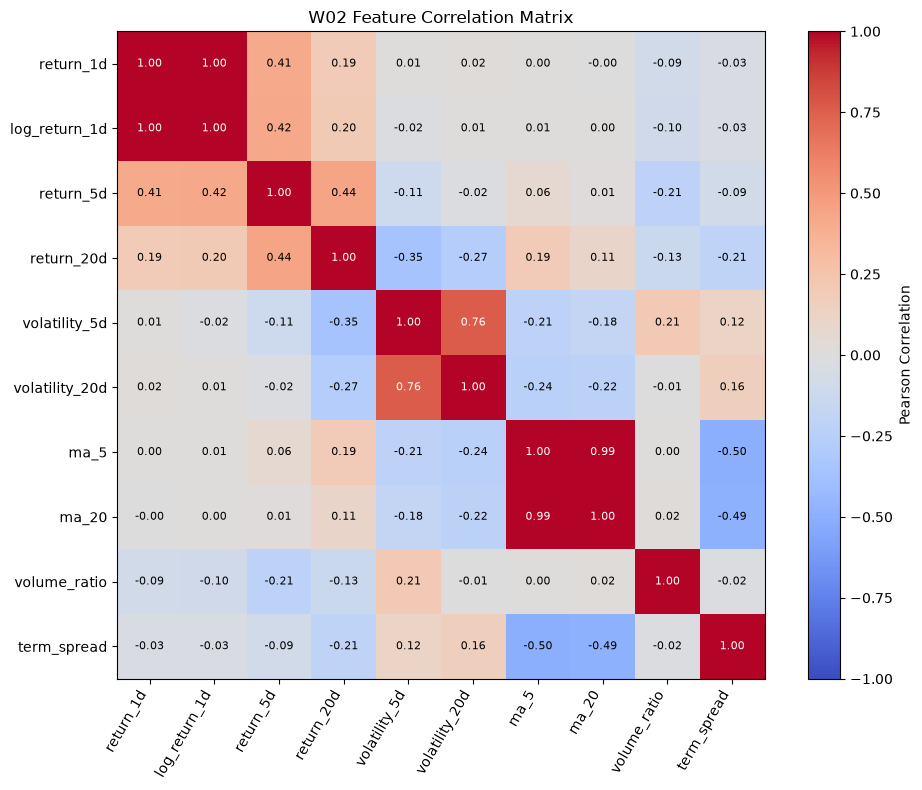

Figure saved successfully!


In [45]:
import matplotlib.pyplot as plt

corr = features_ready[feature_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
for i in range(len(feature_cols)):
    for j in range(len(feature_cols)):
        value = corr.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(value) > 0.6 else "black"
        )

ax.set_xticks(range(len(feature_cols)))
ax.set_yticks(range(len(feature_cols)))

ax.set_xticklabels(feature_cols, rotation=60, ha="right")
ax.set_yticklabels(feature_cols)

fig.colorbar(im, ax=ax, label="Pearson Correlation")

plt.title("W02 Feature Correlation Matrix")
plt.tight_layout()

plt.savefig(
    fig_dir / "W02_Feature_Correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")

In [46]:
figure_path = fig_dir / "W02_Feature_Correlation.png"

print("File exists:", figure_path.exists())
print("Saved at:", figure_path)

File exists: True
Saved at: /Users/sienn/Desktop/Chooser_Option_Research/04_Reports/weekly/figures/W02_Feature_Correlation.png


### Correlation Analysis — Key Observations

- Daily simple returns and log returns are highly correlated.
- The 5-day and 20-day moving averages show strong positive correlation.
- Short-term and medium-term volatility features are positively correlated.
- Potential multicollinearity should be considered during ML feature selection.

### Next Step: Feature Importance

Two target-specific analyses are planned:

1. Volatility forecasting: importance for predicting future realized volatility.
2. Direct pricing: importance for predicting simulated Chooser Option prices.

These analyses will be conducted after the corresponding targets and models are established.